# Variational Quantum Eigensolver

The Variational Quantum Eigensolver (VQE) is a hybrid quantum-classical algorithm that approximates the lowest eigenvalue of a Hamiltonian $H$ [1, 2]. It is based on the variational principle: for any normalized state $|\psi\rangle$,

$$E(\vec\theta) = \langle \psi(\vec\theta) | H | \psi(\vec\theta) \rangle \geq E_0,$$

where $E_0$ is the ground state energy. VQE prepares a trial state $|\psi(\vec\theta)\rangle = U(\vec\theta)|\psi_0\rangle$ with a parameterized quantum circuit, called the ansatz, and repeats the following loop:

1. The quantum computer prepares $|\psi(\vec\theta)\rangle$ and estimates $E(\vec\theta)$. The Hamiltonian is written as a weighted sum of Pauli strings, $H = \sum_j c_j P_j$, and each expectation value $\langle P_j \rangle$ is estimated from measurements.
2. A classical optimizer proposes new parameters $\vec\theta$ that lower the energy.

Because the quantum circuits are short and each one is run independently, VQE is one of the leading candidates for chemistry and materials simulation on near-term quantum devices [3, 4, 5].

In this notebook we use VQE to compute the ground state energy of the hydrogen molecule, H$_2$. We
* build the qubit Hamiltonian of H$_2$,
* run VQE with a chemistry-inspired unitary coupled cluster ansatz on a local simulator,
* compute the potential energy curve of H$_2$ as the two atoms are pulled apart,
* study how the number of measurement shots limits the precision of the energy, and
* compare against a hardware-efficient ansatz, which can get trapped in local minima.

# References

[1] A. Peruzzo et al., "A variational eigenvalue solver on a photonic quantum processor", [Nature Communications 5, 4213 (2014)](https://www.nature.com/articles/ncomms5213).

[2] J. R. McClean, J. Romero, R. Babbush and A. Aspuru-Guzik, "The theory of variational hybrid quantum-classical algorithms", [New Journal of Physics 18, 023023 (2016)](https://iopscience.iop.org/article/10.1088/1367-2630/18/2/023023).

[3] P. J. J. O'Malley et al., "Scalable Quantum Simulation of Molecular Energies", [Physical Review X 6, 031007 (2016)](https://journals.aps.org/prx/abstract/10.1103/PhysRevX.6.031007).

[4] A. Kandala et al., "Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets", [Nature 549, 242 (2017)](https://www.nature.com/articles/nature23879).

[5] S. McArdle, S. Endo, A. Aspuru-Guzik, S. C. Benjamin and X. Yuan, "Quantum computational chemistry", [Reviews of Modern Physics 92, 015003 (2020)](https://journals.aps.org/rmp/abstract/10.1103/RevModPhys.92.015003).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import openfermion as of
from braket.devices import LocalSimulator
from braket.tracking import Tracker

from braket.experimental.algorithms.variational_quantum_eigensolver import (
    evaluate_energy,
    get_vqe_results,
    group_commuting_terms,
    hamiltonian_from_qubit_operator,
    hardware_efficient_ansatz,
    pauli_exponential_ansatz,
    pauli_rotation,
    run_vqe,
    uccsd_generators,
)

%matplotlib inline

tracker = Tracker().start()  # to keep track of Braket costs
device = LocalSimulator()

# The hydrogen molecule Hamiltonian

We describe H$_2$ in the minimal STO-3G basis, which has two spatial orbitals and therefore four spin orbitals. The Jordan-Wigner transformation maps each spin orbital to one qubit, so the Hamiltonian acts on four qubits. A qubit in state $|1\rangle$ means that the spin orbital is occupied.

[OpenFermion](https://github.com/quantumlib/OpenFermion) ships pre-computed molecular integrals for H$_2$ at a range of bond lengths, so no quantum chemistry package is needed. The helper `load_h2_hamiltonian` loads the integrals, applies the Jordan-Wigner transformation and converts the result into a dictionary that maps Pauli strings to coefficients. The $i$-th character of a Pauli string acts on qubit $i$. The Hartree-Fock (HF) energy is the mean-field approximation, and the full configuration interaction (FCI) energy is the exact ground state energy in this basis, which VQE aims to reproduce.

In [2]:
def load_h2_hamiltonian(bond_length):
    molecule = of.MolecularData(
        [("H", (0, 0, 0)), ("H", (0, 0, bond_length))],
        basis="sto-3g",
        multiplicity=1,
        description=str(bond_length),
    )
    molecule.load()
    fermion_hamiltonian = of.get_fermion_operator(molecule.get_molecular_hamiltonian())
    qubit_hamiltonian = of.jordan_wigner(fermion_hamiltonian)
    return molecule, hamiltonian_from_qubit_operator(qubit_hamiltonian, molecule.n_qubits)


molecule, hamiltonian = load_h2_hamiltonian(0.7414)  # equilibrium bond length in Angstrom
n_qubits, n_electrons = molecule.n_qubits, molecule.n_electrons

print(f"Qubits: {n_qubits}, electrons: {n_electrons}, Pauli terms: {len(hamiltonian)}\n")
for pauli_string, coefficient in sorted(hamiltonian.items(), key=lambda t: -abs(t[1])):
    print(f"{coefficient:+.6f}  {pauli_string}")
print(f"\nHartree-Fock energy: {molecule.hf_energy:.6f} Ha")
print(f"FCI energy:          {molecule.fci_energy:.6f} Ha")

Qubits: 4, electrons: 2, Pauli terms: 15

-0.222786  IIZI
-0.222786  IIIZ
+0.174348  IIZZ
+0.171198  IZII
+0.171198  ZIII
+0.168622  ZZII
+0.165867  ZIIZ
+0.165867  IZZI
+0.120545  ZIZI
+0.120545  IZIZ
-0.098864  IIII
+0.045322  YXXY
-0.045322  YYXX
-0.045322  XXYY
+0.045322  XYYX

Hartree-Fock energy: -1.116684 Ha
FCI energy:          -1.137270 Ha


# The unitary coupled cluster ansatz

The Hartree-Fock state places the two electrons in the two lowest spin orbitals, $|\psi_0\rangle = |1100\rangle$. The unitary coupled cluster singles and doubles (UCCSD) ansatz [1, 5] adds electron correlation by applying excitation operators to this reference state,

$$|\psi(\vec\theta)\rangle = \prod_k e^{\theta_k (T_k - T_k^\dagger)} |\psi_0\rangle,$$

where each $T_k$ moves one or two electrons from occupied to unoccupied spin orbitals. The function `uccsd_generators` returns the Jordan-Wigner encoded generators $G_k = i(T_k - T_k^\dagger) = \sum_j c_{kj} P_{kj}$, keeping only excitations that conserve spin. For H$_2$ there are two single excitations and one double excitation.

In [3]:
generators = uccsd_generators(n_qubits, n_electrons)
for k, generator in enumerate(generators):
    terms = " ".join(f"{c:+.3f}*{p}" for p, c in generator.items())
    print(f"G_{k} = {terms}")

G_0 = -0.500*YZXI +0.500*XZYI
G_1 = -0.500*IYZX +0.500*IXZY
G_2 = +0.125*XXYX -0.125*YYYX +0.125*YXYY +0.125*XYYY -0.125*YXXX -0.125*XYXX +0.125*XXXY -0.125*YYXY


Each exponential $e^{-i\theta_k G_k}$ is a product of Pauli rotations $e^{-i\theta_k c_{kj} P_{kj}}$, which is exact because the Pauli strings of a single excitation commute. A Pauli rotation is implemented by rotating every qubit into the $Z$ basis, computing the parity with a ladder of CNOT gates, applying an $R_z$ rotation, and undoing the previous steps. Here is the circuit for $e^{-i \frac{\phi}{2} X_0 Z_1 Y_2}$:

In [4]:
print(pauli_rotation("XZY", 0.5))

T  : │     0      │  1  │  2  │     3      │  4  │      5      │  6  │
         ┌───┐                                                  ┌───┐ 
q0 : ────┤ H ├───────●──────────────────────────────────●───────┤ H ├─
         └───┘       │                                  │       └───┘ 
                   ┌─┴─┐                              ┌─┴─┐           
q1 : ──────────────┤ X ├───●──────────────────●───────┤ X ├───────────
                   └───┘   │                  │       └───┘           
      ┌──────────┐       ┌─┴─┐ ┌──────────┐ ┌─┴─┐ ┌───────────┐       
q2 : ─┤ Rx(1.57) ├───────┤ X ├─┤ Rz(0.50) ├─┤ X ├─┤ Rx(-1.57) ├───────
      └──────────┘       └───┘ └──────────┘ └───┘ └───────────┘       
T  : │     0      │  1  │  2  │     3      │  4  │      5      │  6  │


In [5]:
initial_state = [1] * n_electrons + [0] * (n_qubits - n_electrons)  # Hartree-Fock state
ansatz = pauli_exponential_ansatz(generators, initial_state=initial_state)

gate_counts = {}
for instruction in ansatz.instructions:
    gate_counts[instruction.operator.name] = gate_counts.get(instruction.operator.name, 0) + 1
print(f"Parameters: {sorted(p.name for p in ansatz.parameters)}")
print(f"Depth: {ansatz.depth}, gate counts: {gate_counts}")

Parameters: ['theta_0', 'theta_1', 'theta_2']
Depth: 100, gate counts: {'X': 2, 'Rx': 40, 'H': 40, 'CNot': 64, 'Rz': 12}


# Run VQE on a local simulator

We start from $\vec\theta = 0$, which is exactly the Hartree-Fock state, and minimize the energy with the gradient-free COBYLA optimizer from SciPy. With `shots=0` the local simulator computes exact expectation values, so the only error left is the error of the ansatz and of the optimizer.

In [6]:
vqe_result = run_vqe(device, hamiltonian, ansatz, np.zeros(len(generators)), shots=0)
summary = get_vqe_results(vqe_result, exact_energy=molecule.fci_energy)
print(f"Optimal parameters:  {np.round(vqe_result['optimal_parameters'], 4)}")

VQE energy:          -1.137270
Energy evaluations:  46
Exact energy:        -1.137270
Absolute error:      1.50e-09
Chemical accuracy:   True
Optimal parameters:  [-0.      0.     -0.1131]


VQE reproduces the FCI energy far below chemical accuracy, $1.6\times 10^{-3}$ Ha (about 1 kcal/mol), which is the precision needed for chemically meaningful predictions. The two single-excitation amplitudes are zero: for H$_2$, symmetry forbids single excitations from mixing with the Hartree-Fock state, and all the correlation energy comes from the double excitation. The convergence of the optimizer is shown below.

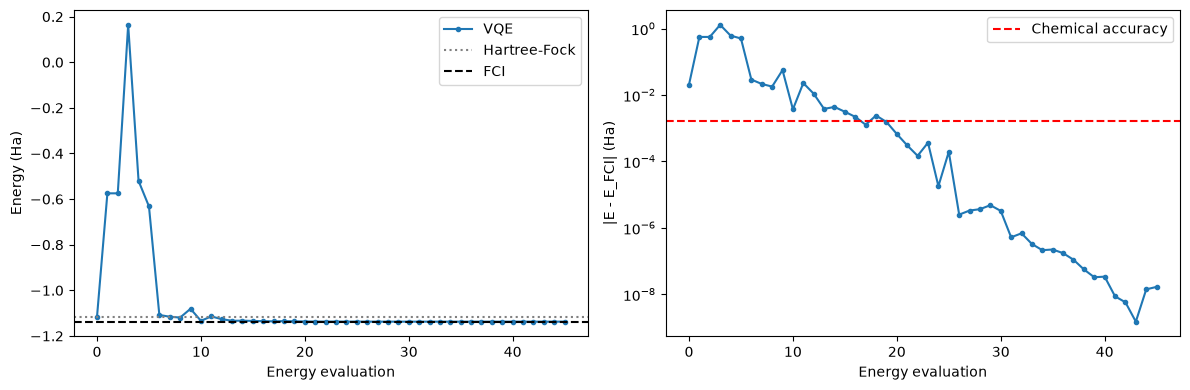

In [7]:
energy_history = np.array(vqe_result["energy_history"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(energy_history, marker=".", label="VQE")
ax1.axhline(molecule.hf_energy, color="gray", linestyle=":", label="Hartree-Fock")
ax1.axhline(molecule.fci_energy, color="black", linestyle="--", label="FCI")
ax1.set_xlabel("Energy evaluation")
ax1.set_ylabel("Energy (Ha)")
ax1.legend()

ax2.semilogy(np.abs(energy_history - molecule.fci_energy), marker=".")
ax2.axhline(1.6e-3, color="red", linestyle="--", label="Chemical accuracy")
ax2.set_xlabel("Energy evaluation")
ax2.set_ylabel("|E - E_FCI| (Ha)")
ax2.legend()
plt.tight_layout()
plt.show()

# Potential energy curve

Next we repeat the calculation as the H$_2$ bond is stretched. Mean-field theory fails badly at large bond lengths, where the two electrons localize on separate atoms and the state is strongly correlated. Each point starts the optimizer from the parameters found at the previous bond length. Because the simulation is exact, we use the BFGS optimizer, which estimates gradients by finite differences and converges in a few iterations.

In [8]:
bond_lengths = np.round(np.arange(0.3, 3.01, 0.1), 1)
hf_energies, fci_energies, vqe_energies = [], [], []

parameters = np.zeros(len(generators))
for bond_length in bond_lengths:
    molecule_r, hamiltonian_r = load_h2_hamiltonian(bond_length)
    result = run_vqe(device, hamiltonian_r, ansatz, parameters, optimizer="BFGS")
    parameters = result["optimal_parameters"]
    hf_energies.append(molecule_r.hf_energy)
    fci_energies.append(molecule_r.fci_energy)
    vqe_energies.append(result["optimal_energy"])

errors = np.abs(np.array(vqe_energies) - np.array(fci_energies))
print(f"Largest deviation from FCI along the curve: {errors.max():.2e} Ha")

Largest deviation from FCI along the curve: 3.25e-11 Ha


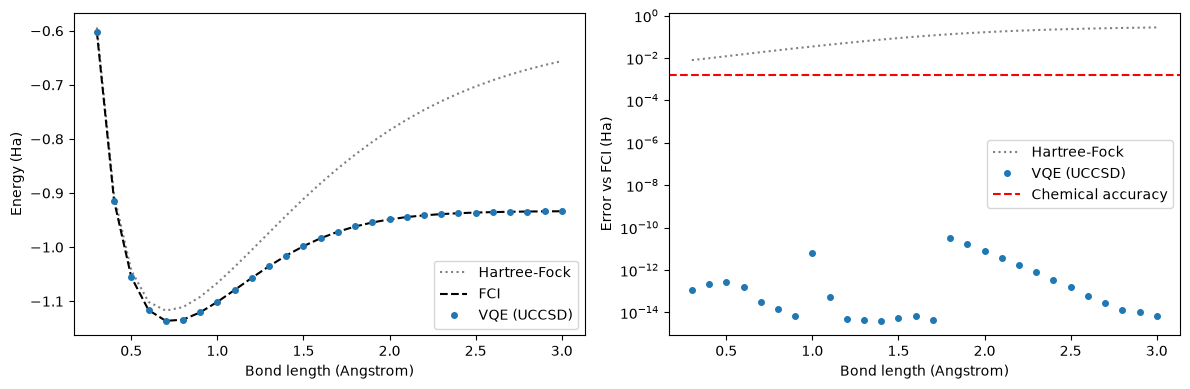

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(bond_lengths, hf_energies, ":", color="gray", label="Hartree-Fock")
ax1.plot(bond_lengths, fci_energies, "--", color="black", label="FCI")
ax1.plot(bond_lengths, vqe_energies, "o", markersize=4, label="VQE (UCCSD)")
ax1.set_xlabel("Bond length (Angstrom)")
ax1.set_ylabel("Energy (Ha)")
ax1.legend()

ax2.semilogy(
    bond_lengths,
    np.array(hf_energies) - np.array(fci_energies),
    ":",
    color="gray",
    label="Hartree-Fock",
)
ax2.semilogy(bond_lengths, np.maximum(errors, 1e-16), "o", markersize=4, label="VQE (UCCSD)")
ax2.axhline(1.6e-3, color="red", linestyle="--", label="Chemical accuracy")
ax2.set_xlabel("Bond length (Angstrom)")
ax2.set_ylabel("Error vs FCI (Ha)")
ax2.legend()
plt.tight_layout()
plt.show()

VQE follows the exact curve at every bond length, while the Hartree-Fock error grows to more than 0.2 Ha as the molecule dissociates.

# Measuring the energy with a finite number of shots

On a quantum computer the expectation values $\langle P_j \rangle$ are not available exactly. They are estimated by repeating the circuit for a number of shots and measuring every qubit. Pauli strings that agree on every qubit where both act non-trivially are called qubit-wise commuting, and can be measured from the same shots after rotating each qubit into the right basis. `group_commuting_terms` partitions the Hamiltonian into such groups, and `evaluate_energy` with `shots > 0` runs one circuit per group.

In [10]:
groups = group_commuting_terms(hamiltonian)
print(f"{len(hamiltonian) - 1} non-identity terms are measured with {len(groups)} circuits:")
for group in groups:
    print("  ", group)

14 non-identity terms are measured with 5 circuits:
   ['IIZI', 'IIIZ', 'IIZZ', 'IZII', 'ZIII', 'ZZII', 'ZIIZ', 'IZZI', 'ZIZI', 'IZIZ']
   ['YXXY']
   ['YYXX']
   ['XXYY']
   ['XYYX']


The energy estimate is now a random variable. We evaluate the energy at the optimal parameters 20 times for several shot counts, and measure the spread of the estimates.

In [11]:
optimal_parameters = vqe_result["optimal_parameters"]
shot_counts = [100, 1000, 10000]
estimates = {
    shots: [
        evaluate_energy(device, ansatz, hamiltonian, optimal_parameters, shots=shots)
        for _ in range(20)
    ]
    for shots in shot_counts
}
for shots, values in estimates.items():
    print(
        f"{shots:>6} shots per circuit: mean {np.mean(values):.4f} Ha, std {np.std(values):.4f} Ha"
    )

   100 shots per circuit: mean -1.1342 Ha, std 0.0203 Ha
  1000 shots per circuit: mean -1.1385 Ha, std 0.0058 Ha
 10000 shots per circuit: mean -1.1367 Ha, std 0.0019 Ha


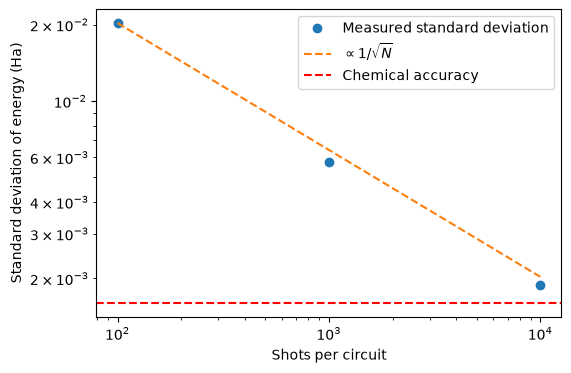

Approximate number of shots per circuit for chemical accuracy: 16107


In [12]:
stds = np.array([np.std(estimates[shots]) for shots in shot_counts])
reference = stds[0] * np.sqrt(shot_counts[0] / np.array(shot_counts))
shots_needed = shot_counts[0] * (stds[0] / 1.6e-3) ** 2

plt.figure(figsize=(6, 4))
plt.loglog(shot_counts, stds, "o", label="Measured standard deviation")
plt.loglog(shot_counts, reference, "--", label=r"$\propto 1/\sqrt{N}$")
plt.axhline(1.6e-3, color="red", linestyle="--", label="Chemical accuracy")
plt.xlabel("Shots per circuit")
plt.ylabel("Standard deviation of energy (Ha)")
plt.legend()
plt.show()
print(f"Approximate number of shots per circuit for chemical accuracy: {shots_needed:.0f}")

The statistical error decreases as $1/\sqrt{N}$, so reaching chemical accuracy for even this small molecule needs more than ten thousand shots per circuit, for every energy evaluation of the optimization. The measurement cost is one of the main challenges of VQE. It can be reduced by grouping terms into fewer circuits, and by distributing shots unevenly between the groups. The [adaptive shot allocation](../advanced_algorithms/adaptive_shot_allocation/2_Adaptive_Shot_Allocation.ipynb) notebook in this library shows how to do this for the same kind of Pauli-sum Hamiltonians.

# The hardware-efficient ansatz

The UCCSD circuit above contains 64 CNOT gates for only three parameters, which is too deep for most of today's quantum processors. A common alternative is the hardware-efficient ansatz [4], which alternates layers of single-qubit rotations with entangling gates that are native to the device. It is shallow and flexible, but it does not encode any chemistry. At the equilibrium bond length a single layer of the hardware-efficient ansatz usually finds the ground state. Here we stretch the bond to 1.5 Angstrom, where electron correlation is stronger, and run VQE from five different random starting points.

In [13]:
molecule_stretched, hamiltonian_stretched = load_h2_hamiltonian(1.5)
hea = hardware_efficient_ansatz(n_qubits, n_layers=1, initial_state=initial_state)
n_parameters = len(hea.parameters)
cnot_count = sum(instruction.operator.name == "CNot" for instruction in hea.instructions)
print(f"Hardware-efficient ansatz: {n_parameters} parameters, {cnot_count} CNOT gates\n")

rng = np.random.default_rng(seed=7)
for trial in range(5):
    initial_parameters = rng.normal(0, 0.1, n_parameters)
    result = run_vqe(device, hamiltonian_stretched, hea, initial_parameters, optimizer="L-BFGS-B")
    error = result["optimal_energy"] - molecule_stretched.fci_energy
    print(f"Trial {trial}: energy {result['optimal_energy']:.6f} Ha, error {error:.1e} Ha")

Hardware-efficient ansatz: 8 parameters, 3 CNOT gates



Trial 0: energy -0.998149 Ha, error 1.2e-11 Ha


Trial 1: energy -0.998149 Ha, error 4.1e-11 Ha


Trial 2: energy -0.890585 Ha, error 1.1e-01 Ha


Trial 3: energy -0.890585 Ha, error 1.1e-01 Ha


Trial 4: energy -0.910874 Ha, error 8.7e-02 Ha


The hardware-efficient ansatz uses only three CNOT gates, but whether it reaches the ground state depends on where the optimizer starts. Some runs converge to the FCI energy, while others get stuck in a local minimum about 0.1 Ha above it, worse than chemical accuracy by almost two orders of magnitude. The UCCSD ansatz reached the FCI energy at this bond length in the potential energy curve above. This illustrates a central trade-off in VQE: problem-inspired ansätze such as UCCSD are reliable but deep, while hardware-efficient ansätze are shallow but harder to train, and become even harder to train as the number of qubits grows.

# [Optional] Run on a QPU or on-demand simulator

To run on Amazon Braket, replace the `LocalSimulator` with an `AwsDevice`. A full optimization needs dozens of energy evaluations, so we only evaluate the energy once at the optimal parameters found above. With `shots=1000` this submits one task per measurement group, five tasks in total. On the SV1 on-demand simulator, at \$0.075 per minute with a minimum of 3 seconds billed per task, this costs about \$0.02. On the IQM Garnet QPU, at \$0.30 per task and \$0.00145 per shot, it costs about \$8.75. On current QPUs, noise in the deep UCCSD circuit will shift the measured energy away from the FCI value, and error mitigation techniques are needed to recover accurate results.

In [14]:
# # Uncomment to run on an Amazon Braket device
# from braket.aws import AwsDevice

# aws_device = AwsDevice("arn:aws:braket:::device/quantum-simulator/amazon/sv1")  # on-demand simulator
# # aws_device = AwsDevice("arn:aws:braket:eu-north-1::device/qpu/iqm/Garnet")  # QPU
# energy = evaluate_energy(aws_device, ansatz, hamiltonian, optimal_parameters, shots=1000)
# print(f"Energy measured on {aws_device.name}: {energy:.6f} Ha (FCI: {molecule.fci_energy:.6f} Ha)")

In [15]:
print("Task Summary")
print(f"{tracker.quantum_tasks_statistics()} \n")
print(
    f"Estimated cost to run this example: {tracker.qpu_tasks_cost() + tracker.simulator_tasks_cost():.2f} USD"
)

Task Summary
{} 

Estimated cost to run this example: 0.00 USD


Note: Charges shown are estimates based on your Amazon Braket simulator and quantum processing unit (QPU) task usage. Estimated charges shown may differ from your actual charges. Estimated charges do not factor in any discounts or credits, and you may experience additional charges based on your use of other services such as Amazon Elastic Compute Cloud (Amazon EC2).

# Summary

In this notebook we used the variational quantum eigensolver to compute the ground state energy of H$_2$. With the UCCSD ansatz, VQE reproduced the exact FCI energy along the whole dissociation curve on a noiseless simulator. We saw that estimating the energy from measurements requires many shots to reach chemical accuracy, and that shallow hardware-efficient ansätze can get trapped in local minima. The functions used here work with any Hamiltonian given as a sum of Pauli strings, so the same workflow can be applied to other molecules or to spin models.